# Detecção de objetos em imagem com YOLOv3 + OpenCV

Este notebook carrega uma imagem, passa ela pelo **YOLOv3** (pré-treinado no COCO) usando o módulo `dnn` do OpenCV e desenha as caixas dos objetos detectados.

O pipeline é o mesmo do [`yolo_detect_video.py`](yolo_detect_video.py), mas separado em etapas para estudo. Os limiares e os erros encontrados estão explicados no [README](README.md).

**Etapas:**
1. Instalação e imports
2. Caminhos e parâmetros
3. Leitura e pré-processamento da imagem
4. Classes e cores
5. Carregamento do modelo e inferência
6. Filtragem das detecções
7. Non-Maximum Suppression (NMS)
8. Desenho e exibição do resultado

## 1. Instalação e imports

Rode a célula de instalação uma vez. Os pesos do modelo não vêm no repositório: baixe com `python download_models.py`.

In [ ]:
%pip install -r requirements.txt

In [2]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

print("OpenCV", cv2.__version__)

OpenCV 4.14.0


## 2. Caminhos e parâmetros

```
├── yolo_detect_image.ipynb
├── samples/yoloTeste.jpg
└── models/
    ├── coco.names
    ├── yolov3.cfg / yolov3.weights            (modelo completo)
    └── yolov3-tiny.cfg / yolov3-tiny.weights  (versão leve)
```

Para testar o modelo leve, troque `MODEL_NAME` para `"yolov3-tiny"`.

In [3]:
# O Jupyter roda com a pasta do notebook como diretório atual
BASE_DIR = Path.cwd()
MODELS_DIR = BASE_DIR / "models"

# Imagem que será analisada
IMG_PATH = BASE_DIR / "samples" / "yoloTeste.jpg"

# Modelo: "yolov3" (mais preciso) ou "yolov3-tiny" (mais rápido)
MODEL_NAME = "yolov3"

# Limiares (ver "Por que dois limiares?" no README)
CONF_THRESHOLD = 0.5  # confiança mínima: "tem objeto?"
NMS_THRESHOLD = 0.4   # IoU máximo entre caixas: "é duplicata?"
INPUT_SIZE = 416      # 320, 416 ou 608: mesmos pesos, só muda o blob

## 3. Leitura e pré-processamento da imagem

O OpenCV lê a imagem como um array NumPy. Depois ela é convertida em um **blob**, o formato de entrada que a rede espera.

In [4]:
# Lê a imagem como um array NumPy (altura, largura, 3)
# Atenção: o OpenCV carrega os canais na ordem BGR, não RGB
img_to_detect = cv2.imread(str(IMG_PATH))

# cv2.imread não gera erro se o arquivo não existir, só retorna None
if img_to_detect is None:
    raise FileNotFoundError(f"Imagem não encontrada: {IMG_PATH}")

# O YOLO devolve coordenadas normalizadas (0 a 1); estas dimensões
# servem para converter de volta para pixels
img_height, img_width = img_to_detect.shape[:2]
print(f"{img_width}x{img_height}")

565x353


In [5]:
img_blob = cv2.dnn.blobFromImage(
    img_to_detect,
    1 / 255,                    # escala os pixels de 0–255 para 0–1
    (INPUT_SIZE, INPUT_SIZE),   # tamanho de entrada da rede
    swapRB=True,                # BGR -> RGB (a rede foi treinada em RGB)
    crop=False,                 # só redimensiona, sem cortar (a proporção é distorcida)
)
print(img_blob.shape)  # (batch, canais, altura, largura)

(1, 3, 416, 416)


## 4. Classes e cores

As 80 classes do COCO ficam em `models/coco.names`, uma por linha. Cada classe recebe uma cor para o desenho das caixas.

In [6]:
# A ORDEM IMPORTA: o índice devolvido pela rede é a posição nesta lista
# (ex.: 0 = "person", 2 = "car")
class_labels = (MODELS_DIR / "coco.names").read_text(encoding="utf-8").splitlines()
print(len(class_labels), "classes")

80 classes


In [7]:
# 5 cores base (B, G, R), repetidas 16 vezes: 5 x 16 = 80, uma por classe
# As cores se repetem a cada 5 classes, por isso a legenda é necessária
BASE_COLORS = np.array([(0, 255, 0), (0, 0, 255), (255, 0, 0), (255, 255, 0), (0, 255, 255)])
CLASS_COLORS = np.tile(BASE_COLORS, (16, 1))  # formato final: (80, 3)

## 5. Carregamento do modelo e inferência

O modelo está no formato **Darknet** (framework original do YOLO). O blob é passado pela rede (*forward pass*) e são coletadas as saídas das camadas de detecção.

In [8]:
# .cfg     -> arquitetura da rede (camadas, filtros, anchors)
# .weights -> pesos treinados no COCO
model_cfg = MODELS_DIR / f"{MODEL_NAME}.cfg"
model_weights = MODELS_DIR / f"{MODEL_NAME}.weights"
if not model_weights.exists():
    raise FileNotFoundError(f"{model_weights} não encontrado. Rode: python download_models.py {MODEL_NAME}")

yolo_model = cv2.dnn.readNetFromDarknet(str(model_cfg), str(model_weights))
# Usa a GPU via OpenCL (~2.5x mais rápido); sem OpenCL, o OpenCV volta sozinho para a CPU
yolo_model.setPreferableTarget(cv2.dnn.DNN_TARGET_OPENCL)

# Camadas de saída = as que não alimentam nenhuma outra.
# YOLOv3: 3 grades (13x13, 26x26, 52x52). YOLOv3-tiny: 2 (13x13, 26x26)
yolo_output_layers = yolo_model.getUnconnectedOutLayersNames()
print(yolo_output_layers)

('yolo_82', 'yolo_94', 'yolo_106')


In [9]:
yolo_model.setInput(img_blob)

# Junta as saídas de todas as camadas numa única matriz.
# Cada LINHA é uma caixa candidata com 85 valores:
#   [0:4]  -> center_x, center_y, width, height (normalizados 0–1)
#   [4]    -> objectness (chance de existir algum objeto ali)
#   [5:85] -> score de cada uma das 80 classes
outputs = np.vstack(yolo_model.forward(yolo_output_layers))
print(outputs.shape)

(10647, 85)


## 6. Filtragem das detecções

A rede gera milhares de caixas candidatas. Ficam só as com confiança acima de `CONF_THRESHOLD`, já convertidas para pixels. As operações são feitas em todas as linhas de uma vez (vetorizadas), sem `for`.

In [10]:
scores = outputs[:, 5:]

# class_id = POSIÇÃO do maior score (qual objeto é)
class_ids = scores.argmax(axis=1)
# confidence = VALOR desse score (quanta certeza o modelo tem)
confidences = scores[np.arange(len(scores)), class_ids]

# O argmax sempre escolhe alguma classe; o limiar decide se existe objeto ali
keep = confidences >= CONF_THRESHOLD

# De fração para pixel: [cx, cy, w, h] x [largura, altura, largura, altura]
boxes = outputs[keep, 0:4] * np.array([img_width, img_height, img_width, img_height])
# Do centro para o canto superior esquerdo: anda metade do tamanho para trás
boxes[:, 0:2] -= boxes[:, 2:4] / 2

# Listas alinhadas: a mesma posição em cada lista é a mesma detecção
boxes_list = boxes.astype(int).tolist()        # [start_x, start_y, largura, altura]
class_ids_list = class_ids[keep].tolist()
confidences_list = confidences[keep].tolist()
print(len(boxes_list), "caixas antes do NMS")

20 caixas antes do NMS


## 7. Non-Maximum Suppression (NMS)

O mesmo objeto costuma ser detectado por várias caixas sobrepostas. O NMS mantém a de maior confiança e descarta as que se sobrepõem demais a ela (IoU acima de `NMS_THRESHOLD`).

In [11]:
# O mesmo CONF_THRESHOLD do filtro, para os dois não filtrarem de formas diferentes.
# O formato do retorno muda entre versões do OpenCV; o flatten padroniza
nms_ids = np.array(
    cv2.dnn.NMSBoxes(boxes_list, confidences_list, CONF_THRESHOLD, NMS_THRESHOLD), dtype=int
).flatten()
print(len(nms_ids), "caixas depois do NMS")

4 caixas depois do NMS


## 8. Desenho e exibição do resultado

O desenho é feito numa cópia, para a imagem original continuar limpa se a célula for executada de novo. A exibição usa o matplotlib, porque o `cv2.imshow` trava no Jupyter.

In [12]:
result = img_to_detect.copy()

for idx in nms_ids:
    start_x, start_y, box_width, box_height = boxes_list[idx]
    end_x, end_y = start_x + box_width, start_y + box_height

    class_id = class_ids_list[idx]
    color = [int(c) for c in CLASS_COLORS[class_id]]
    label = f"{class_labels[class_id]}: {confidences_list[idx]:.0%}"
    print(label)

    cv2.rectangle(result, (start_x, start_y), (end_x, end_y), color, 2)
    # Evita que a legenda saia pelo topo da imagem
    cv2.putText(result, label, (start_x, max(start_y - 8, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)

car: 100%
person: 99%
person: 97%
bicycle: 96%


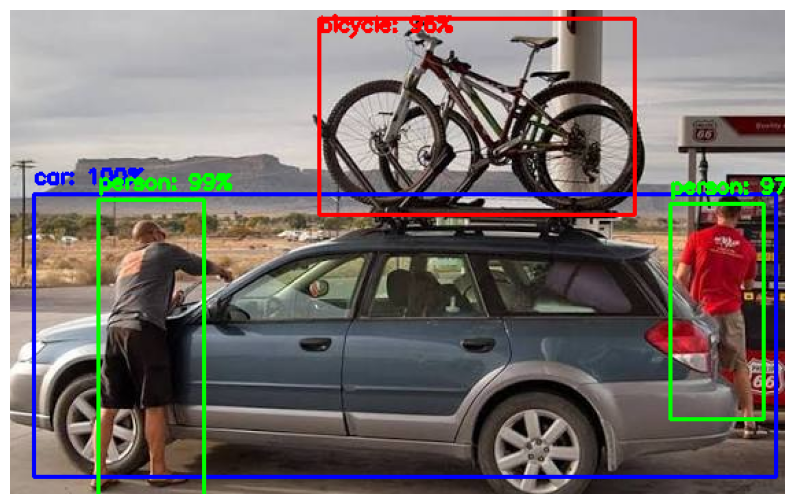

In [13]:
# O matplotlib espera RGB; o OpenCV trabalha em BGR
plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()